# Full-cohort validation experiments

This notebook uses the complete source-family validation cohort. Evidence metrics,
tokenizer retention and answer EM/F1 are separate. Tables and plots are recorded
measurements with exact cohort identities; no test questions are opened here.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import collections, csv, hashlib, html, io, json, math, random, re, statistics, string, subprocess, sys, time, zipfile
import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Run in this repository"
FIGURES = ROOT / "assets/plots"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "svg.fonttype": "none",
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def sha(raw):
    return hashlib.sha256(raw).hexdigest()


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


def table(rows, columns, caption):
    header = "".join("<th>" + html.escape(str(c)) + "</th>" for c in columns)
    body = "".join(
        "<tr>"
        + "".join("<td>" + html.escape(str(r.get(c, ""))) + "</td>" for c in columns)
        + "</tr>"
        for r in rows
    )
    display(
        HTML(
            "<table><caption>"
            + html.escape(caption)
            + "</caption><thead><tr>"
            + header
            + "</tr></thead><tbody>"
            + body
            + "</tbody></table>"
        )
    )


def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + ".png"), dpi=160)
    fig.savefig(FIGURES / (name + ".svg"))
    svg_path = FIGURES / (name + ".svg")
    svg_path.write_text(
        "\n".join(
            line.rstrip() for line in svg_path.read_text(encoding="utf-8").splitlines()
        )
        + "\n",
        encoding="utf-8",
        newline="\n",
    )
    display(SVG(svg_path.read_text(encoding="utf-8")))
    plt.close(fig)


print("Analysis kernel ready. No model weights loaded.")


Analysis kernel ready. No model weights loaded.


In [2]:
retrieval = read_json("docs/full-validation-retrieval.json")
table(
    [
        {
            "QA": retrieval["n"],
            "evidence recall@4": retrieval["recall_at_4"],
            "evidence precision@4": retrieval["precision_at_4"],
            "candidate recall@12": retrieval["candidate_recall_at_12"],
        }
    ],
    ["QA", "evidence recall@4", "evidence precision@4", "candidate recall@12"],
    "Actual all2372-QA BM25 validation; these are evidence metrics, not answer scores",
)
print("Validation IDs SHA256:", retrieval["validation_ids_sha256"])


QA,evidence recall@4,evidence precision@4,candidate recall@12
2372,0.8134134345137718,0.21395446880269814,0.963146430578977


Validation IDs SHA256: 40d2ddd6b065469a8b947d84dbb630efcaac83acecc695606022116cc1a0f7cb


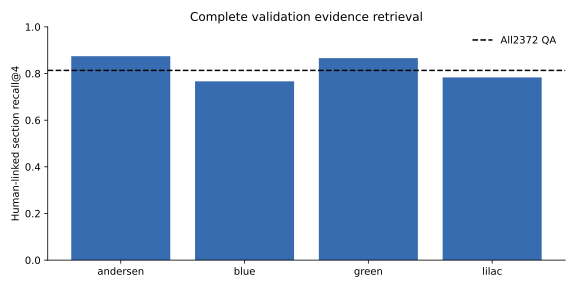

In [3]:
origins = list(retrieval["origin"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    [o.replace("-fairybook", "") for o in origins],
    [retrieval["origin"][o]["recall_at_4"] for o in origins],
    color="#386cb0",
)
ax.axhline(retrieval["recall_at_4"], linestyle="--", color="black", label="All2372 QA")
ax.set(
    ylim=(0, 1),
    ylabel="Human-linked section recall@4",
    title="Complete validation evidence retrieval",
)
ax.legend(frameon=False)
show_figure(fig, "evidence-validation-baseline")


## Context retention

Human-linked sections can be retrieved but lost when the 512-token generator
context is assembled in source order. The following measurement uses the actual
pinned T5 tokenizer and all validation QA without allocating a neural encoder.
Retaining a section ID does not establish that every supporting sentence survives.


In [4]:
retention = read_json("docs/context-retention.json")
table(
    [
        {
            k: retention[k]
            for k in (
                "n",
                "retrieved_evidence_recall",
                "retained_evidence_recall",
                "mean_input_tokens",
                "max_input_tokens",
                "source_valid",
            )
        }
    ],
    [
        "n",
        "retrieved_evidence_recall",
        "retained_evidence_recall",
        "mean_input_tokens",
        "max_input_tokens",
        "source_valid",
    ],
    "Actual pinned-tokenizer assembly; no generated answer scores",
)


n,retrieved_evidence_recall,retained_evidence_recall,mean_input_tokens,max_input_tokens,source_valid
2372,0.8134134345137718,0.5595489038785835,505.83094435075884,509,2372


## Source-family differences

These are complete-family denominators, not equal-sized convenience samples.
Lang labels describe related collections rather than independent populations.


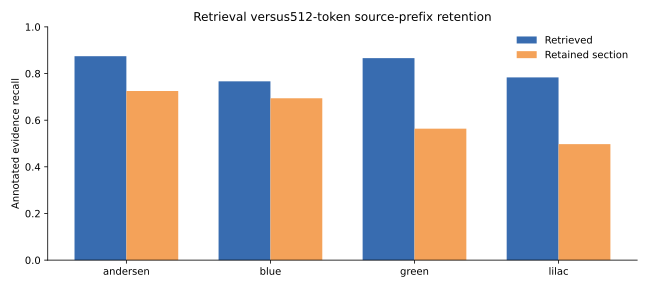

In [5]:
origins = list(retention["per_origin"])
x = np.arange(len(origins))
width = 0.36
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    x - width / 2,
    [retention["per_origin"][o]["retrieved_evidence_recall"] for o in origins],
    width,
    label="Retrieved",
    color="#386cb0",
)
ax.bar(
    x + width / 2,
    [retention["per_origin"][o]["retained_evidence_recall"] for o in origins],
    width,
    label="Retained section",
    color="#f4a259",
)
ax.set_xticks(x, [o.replace("-fairybook", "") for o in origins])
ax.set(
    ylim=(0, 1),
    ylabel="Annotated evidence recall",
    title="Retrieval versus512-token source-prefix retention",
)
ax.legend(frameon=False)
show_figure(fig, "context-retention")


## Full-cohort generator optimization

The cloud run trained T5-small on all 7,883 training questions for three epochs. These saved receipts measure optimization, not answer quality. The initial checkpoint has no training loss. This notebook reads the authenticated aggregate; it does not refit the generator or access test questions.

epoch,mean training loss,training QA
1,1.1786895456597708,7883
2,0.9940754068993648,7883
3,0.9059641202162801,7883


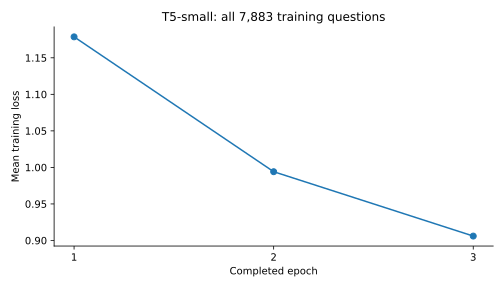

Training runtime: 7.54 hours. Complete answer validation and frozen-test results are in notebooks 05 and 06.


In [3]:
training = read_json("docs/full-generator-training.json")
assert training["training_complete"] and training["training_questions"] == 7883
assert training["epochs_required"] == 3 and training["test_accessed"] is False
assert sha((ROOT / "docs/full-coverage-protocol.json").read_bytes()) == training["protocol_sha256"]
for relative, expected in training["scientific_source_sha256"].items():
    assert sha((ROOT / "src" / relative).read_bytes()) == expected
trained_epochs = [row for row in training["checkpoints"] if row["epoch"] > 0]
assert [row["epoch"] for row in trained_epochs] == [1, 2, 3]
table(
    [{"epoch": row["epoch"], "mean training loss": row["mean_train_loss"],
      "training QA": training["training_questions"]} for row in trained_epochs],
    ["epoch", "mean training loss", "training QA"],
    "Measured complete-cohort generator training",
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([row["epoch"] for row in trained_epochs],
        [row["mean_train_loss"] for row in trained_epochs], marker="o")
ax.set(xlabel="Completed epoch", ylabel="Mean training loss",
       title="T5-small: all 7,883 training questions", xticks=[1, 2, 3])
show_figure(fig, "full-generator-training-loss")
print(f"Training runtime: {training['seconds'] / 3600:.2f} hours. Complete answer validation and frozen-test results are in notebooks 05 and 06.")

## Complete model comparison

Only audited all-query selections are accepted below. Their answer curves come
from actual saved initial/epoch models, never from training loss or interpolation.
No model is selected from test outcomes.


In [7]:
selection_path = ROOT / "docs/full-generator-selection.json"
if selection_path.exists():
    selection = json.loads(selection_path.read_text(encoding="utf-8"))
    assert (
        selection["status"] == "validation_checkpoint_selection"
        and selection["validation_questions"] == 2372
    )
    curve = selection["candidates"]
    table(
        [
            {
                "epoch": r["epoch"],
                "answer F1": r["validation"]["f1"],
                "EM": r["validation"]["em"],
                "n": r["validation"]["n"],
            }
            for r in curve
        ],
        ["epoch", "answer F1", "EM", "n"],
        "Actual complete-validation checkpoint comparison",
    )
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(
        [r["epoch"] for r in curve],
        [r["validation"]["f1"] for r in curve],
        marker="o",
        label="Answer tokenF1",
    )
    ax.plot(
        [r["epoch"] for r in curve],
        [r["validation"]["em"] for r in curve],
        marker="s",
        label="Exact match",
    )
    ax.set(
        xlabel="Saved epoch",
        ylabel="Macro question score",
        title="All2372 validation QA",
    )
    ax.legend(frameon=False)
    show_figure(fig, "full-generator-validation")
else:
    print("Complete model-validation scores unavailable; no score is estimated.")


Complete model-validation scores unavailable; no score is estimated.


## Full generator validation

Every checkpoint decoded all 2,372 validation questions. The fixed token-F1 rule selects epoch 3; these results do not select the final retrieval/context policy or authorize test access. Token F1 rises by about five percentage points from the initial model; differences between trained epochs are small.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
validation_record = json.loads((ROOT / "docs/full-generator-validation.json").read_text(encoding="utf-8"))
assert validation_record["validation_questions"] == 2372
assert validation_record["test_accessed"] is False and validation_record["final_test_authorized"] is False
checkpoint_results = pd.DataFrame([
    {"epoch": row["epoch"], "questions": row["validation"]["n"],
     "token_F1": row["validation"]["f1"], "exact_match": row["validation"]["em"],
     "ROUGE_L": row["validation"]["rouge_l"]}
    for row in validation_record["candidates"]
])
assert list(checkpoint_results.epoch) == [0, 1, 2, 3]
assert set(checkpoint_results.questions) == {2372}
display(checkpoint_results)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(checkpoint_results.epoch, checkpoint_results.token_F1, marker="o", label="Token F1")
ax.plot(checkpoint_results.epoch, checkpoint_results.exact_match, marker="o", label="Exact match")
ax.set(xlabel="Checkpoint epoch (0 = initial)", ylabel="Full-validation score", title="All 2,372 validation questions")
ax.set_xticks([0, 1, 2, 3])
ax.set_ylim(0, .35)
ax.legend()
fig.tight_layout()
path = ROOT / "assets/plots/full-generator-validation.png"
fig.savefig(path, dpi=150)
display(fig)
plt.close(fig)
print("Selected epoch:", validation_record["selected"]["epoch"])
print("Selection SHA256:", validation_record["selection_sha256"])


,epoch,questions,token_F1,exact_match,ROUGE_L
0,0,2372,0.215675,0.099916,0.231625
1,1,2372,0.265383,0.141653,0.288339
2,2,2372,0.265618,0.140809,0.287809
3,3,2372,0.265647,0.141653,0.289173


<Figure size 800x400 with 1 Axes>

Selected epoch: 3
Selection SHA256: 5d1be6e5dadb752af754d3ad36ed05396132fe579d55ec8c8aa0f674da9c30c3


## Selected model by question type

These full-cohort subgroup scores describe where the selected checkpoint struggles; they are not separate model-selection targets. Source citations identify valid coordinates, rather than proving that the answer is supported.

In [9]:
selected_metrics = validation_record["selected"]["validation"]
attribute_results = pd.DataFrame([
    {"attribute": key, "questions": value["n"], "token_F1": value["f1"], "exact_match": value["em"]}
    for key, value in selected_metrics["attribute"].items()
]).sort_values("token_F1")
assert attribute_results.questions.sum() == 2372
display(attribute_results)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(attribute_results.attribute, attribute_results.token_F1, color="#477da7")
ax.set(xlabel="Token F1", title="Selected checkpoint: full validation by question attribute", xlim=(0, 1))
fig.tight_layout()
fig.savefig(ROOT / "assets/plots/full-generator-attributes.png", dpi=150)
display(fig)
plt.close(fig)
display(pd.DataFrame([
    {"question_type": key, "questions": value["n"], "token_F1": value["f1"], "exact_match": value["em"]}
    for key, value in selected_metrics["explicit"].items()
]))


,attribute,questions,token_F1,exact_match
3,feeling,240,0.166560,0.162500
4,outcome resolution,237,0.226090,0.084388
1,causal relationship,667,0.243929,0.070465
5,prediction,52,0.263678,0.153846
0,action,761,0.266404,0.130092
6,setting,148,0.306357,0.209459
2,character,267,0.419738,0.344569


<Figure size 900x400 with 1 Axes>

,question_type,questions,token_F1,exact_match
0,explicit,1625,0.330608,0.198154
1,implicit,747,0.124332,0.018742
